I**T2011 - AI & ML Group Assignment**


Healthcare Diabetes Dataset :End-to-End ML Pipeline

Dataset: Healthcare Diabetes Dataset (Kaggle)


Group Members:

IT25101078 - Nirasha W.A.C

IT25101090 - Jayathilaka W.M.U.S

IT25101091 - Umer D.R.S

IT25101105 - Arachchi B.A.K.S.V

IT25101124 - Weerasekara G.W.D.S

IT25101133 - Kodagoda S.K


In [ ]:
# ---- Setup ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                              confusion_matrix, classification_report, roc_auc_score, roc_curve)

sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

Step 1:Load the dataset

In [ ]:
# ---- Load the dataset from Google Drive ----
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/Healthcare-Diabetes.csv')
df.head()

Mounted at /content/drive


,Id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,1,6,148,72,35,0,33.6,0.627,50,1
1,2,1,85,66,29,0,26.6,0.351,31,0
2,3,8,183,64,0,0,23.3,0.672,32,1
3,4,1,89,66,23,94,28.1,0.167,21,0
4,5,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.info()
print("\nShape:", df.shape)
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2768 entries, 0 to 2767
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        2768 non-null   int64  
 1   Pregnancies               2768 non-null   int64  
 2   Glucose                   2768 non-null   int64  
 3   BloodPressure             2768 non-null   int64  
 4   SkinThickness             2768 non-null   int64  
 5   Insulin                   2768 non-null   int64  
 6   BMI                       2768 non-null   float64
 7   DiabetesPedigreeFunction  2768 non-null   float64
 8   Age                       2768 non-null   int64  
 9   Outcome                   2768 non-null   int64  
dtypes: float64(2), int64(8)
memory usage: 216.4 KB

Shape: (2768, 10)


,count,mean,std,min,25%,50%,75%,max
Id,2768.0,1384.500000,799.197097,1.000,692.750,1384.500,2076.250,2768.00
Pregnancies,2768.0,3.742775,3.323801,0.000,1.000,3.000,6.000,17.00
Glucose,2768.0,121.102601,32.036508,0.000,99.000,117.000,141.000,199.00
BloodPressure,2768.0,69.134393,19.231438,0.000,62.000,72.000,80.000,122.00
SkinThickness,2768.0,20.824422,16.059596,0.000,0.000,23.000,32.000,110.00
Insulin,2768.0,80.127890,112.301933,0.000,0.000,37.000,130.000,846.00
BMI,2768.0,32.137392,8.076127,0.000,27.300,32.200,36.625,80.60
DiabetesPedigreeFunction,2768.0,0.471193,0.325669,0.078,0.244,0.375,0.624,2.42
Age,2768.0,33.132225,11.777230,21.000,24.000,29.000,40.000,81.00
Outcome,2768.0,0.343931,0.475104,0.000,0.000,0.000,1.000,1.00


Step 2: Data Preprocessing and Analysis

### 2.0 Checking for and removing duplicate patient records

Before any cleaning, we checked whether every row represents a genuinely distinct patient. This matters
because if the same patient's record appears more than once and we later split the data into train/test sets,
copies of the same patient can end up on both sides of the split — the model would then be partly "tested" on
data it already memorised during training (data leakage), making every downstream metric look better than it
really is.


In [ ]:
# Check for fully duplicated patient records (same values across every clinical feature + Outcome)
feature_cols_check = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                       'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

n_before = len(df)
n_duplicates = df.duplicated(subset=feature_cols_check).sum()
print(f"Rows before deduplication: {n_before}")
print(f"Fully duplicated patient records found: {n_duplicates}")

df = df.drop_duplicates(subset=feature_cols_check).reset_index(drop=True)
n_after = len(df)
print(f"Rows after deduplication: {n_after}  ({n_after/n_before:.1%} of original rows kept)")
print(f"\nThe dataset supplied ({n_before} rows) turned out to contain only {n_after} unique patients "
      f"— i.e. it is the well-known {n_after}-row Pima Indians Diabetes dataset repeated ~{n_before/n_after:.1f}x. "
      f"All further preprocessing and modelling below uses only the {n_after} unique records.")


2.1 Handling missing data

In [ ]:
# List of columns where a zero value is actually invalid
cols_with_invalid_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("Count of zero values per column (before treatment):")
# Count how many zeros exist in each of these column
print((df[cols_with_invalid_zero] == 0).sum())

df_clean = df.copy()
df_clean[cols_with_invalid_zero] = df_clean[cols_with_invalid_zero].replace(0, np.nan)

print("\nMissing values after converting zeros to NaN:")
print(df_clean.isnull().sum())

imputer = SimpleImputer(strategy='median')
df_clean[cols_with_invalid_zero] = imputer.fit_transform(df_clean[cols_with_invalid_zero])

print("\nMissing values after median imputation:")
print(df_clean.isnull().sum())


Count of zero values per column (before treatment):
Glucose            18
BloodPressure     125
SkinThickness     800
Insulin          1330
BMI                39
dtype: int64

Missing values after converting zeros to NaN:
Id                             0
Pregnancies                    0
Glucose                       18
BloodPressure                125
SkinThickness                800
Insulin                     1330
BMI                           39
DiabetesPedigreeFunction       0
Age                            0
Outcome                        0
dtype: int64

Missing values after median imputation:
Id                          0
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


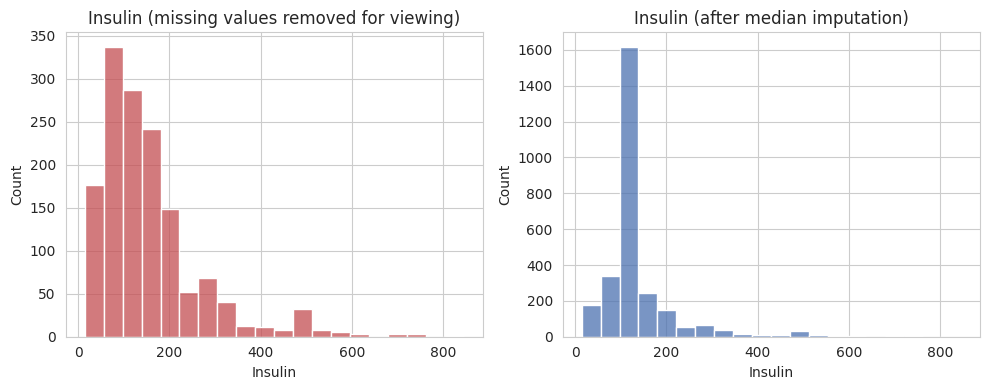

In [ ]:
# EDA visualization for Member 1: distribution before vs after imputation (example: Insulin)
fig, axes = plt.subplots(1, 2, figsize=(10,4))
sns.histplot(df['Insulin'].replace(0, np.nan).dropna(), ax=axes[0], color='#C44E52', bins=20)
axes[0].set_title('Insulin (missing values removed for viewing)')
sns.histplot(df_clean['Insulin'], ax=axes[1], color='#4C72B0', bins=20)
axes[1].set_title('Insulin (after median imputation)')
plt.tight_layout()
plt.show()


2.2 Encoding categorical variables

In [ ]:
df_enc = df_clean.copy()

# Derive a categorical variable to encode
df_enc['BMI_Category'] = pd.cut(df_enc['BMI'], bins=[0, 18.5, 25, 30, 100],
                                 labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

print(df_enc['BMI_Category'].value_counts())

# One-hot encode
df_enc = pd.get_dummies(df_enc, columns=['BMI_Category'], drop_first=True)
df_enc.head()


BMI_Category
Obese          1720
Overweight      658
Normal          376
Underweight      14
Name: count, dtype: int64


,Id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,BMI_Category_Normal,BMI_Category_Overweight,BMI_Category_Obese
0,1,6,148.0,72.0,35.0,126.0,33.6,0.627,50,1,False,False,True
1,2,1,85.0,66.0,29.0,126.0,26.6,0.351,31,0,False,True,False
2,3,8,183.0,64.0,29.0,126.0,23.3,0.672,32,1,True,False,False
3,4,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,False,True,False
4,5,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,False,False,True


/tmp/ipykernel_4619/512145461.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pd.cut(df_clean['BMI'], bins=[0,18.5,25,30,100],


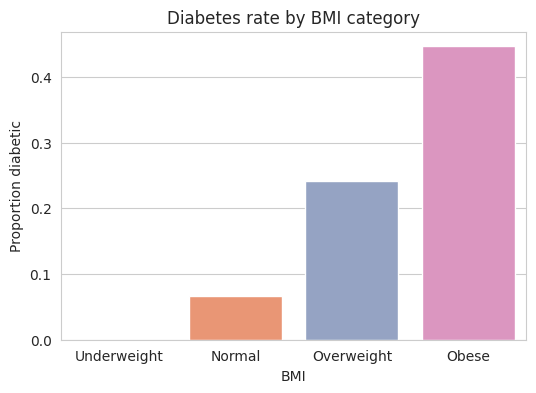

In [ ]:
# EDA visualization for Member 2: outcome rate by BMI category
plt.figure(figsize=(6,4))
sns.barplot(x=pd.cut(df_clean['BMI'], bins=[0,18.5,25,30,100],
                      labels=['Underweight','Normal','Overweight','Obese']),
            y=df_clean['Outcome'], palette='Set2', errorbar=None)
plt.ylabel('Proportion diabetic')
plt.title('Diabetes rate by BMI category')
plt.show()


### 2.3 Outlier removal


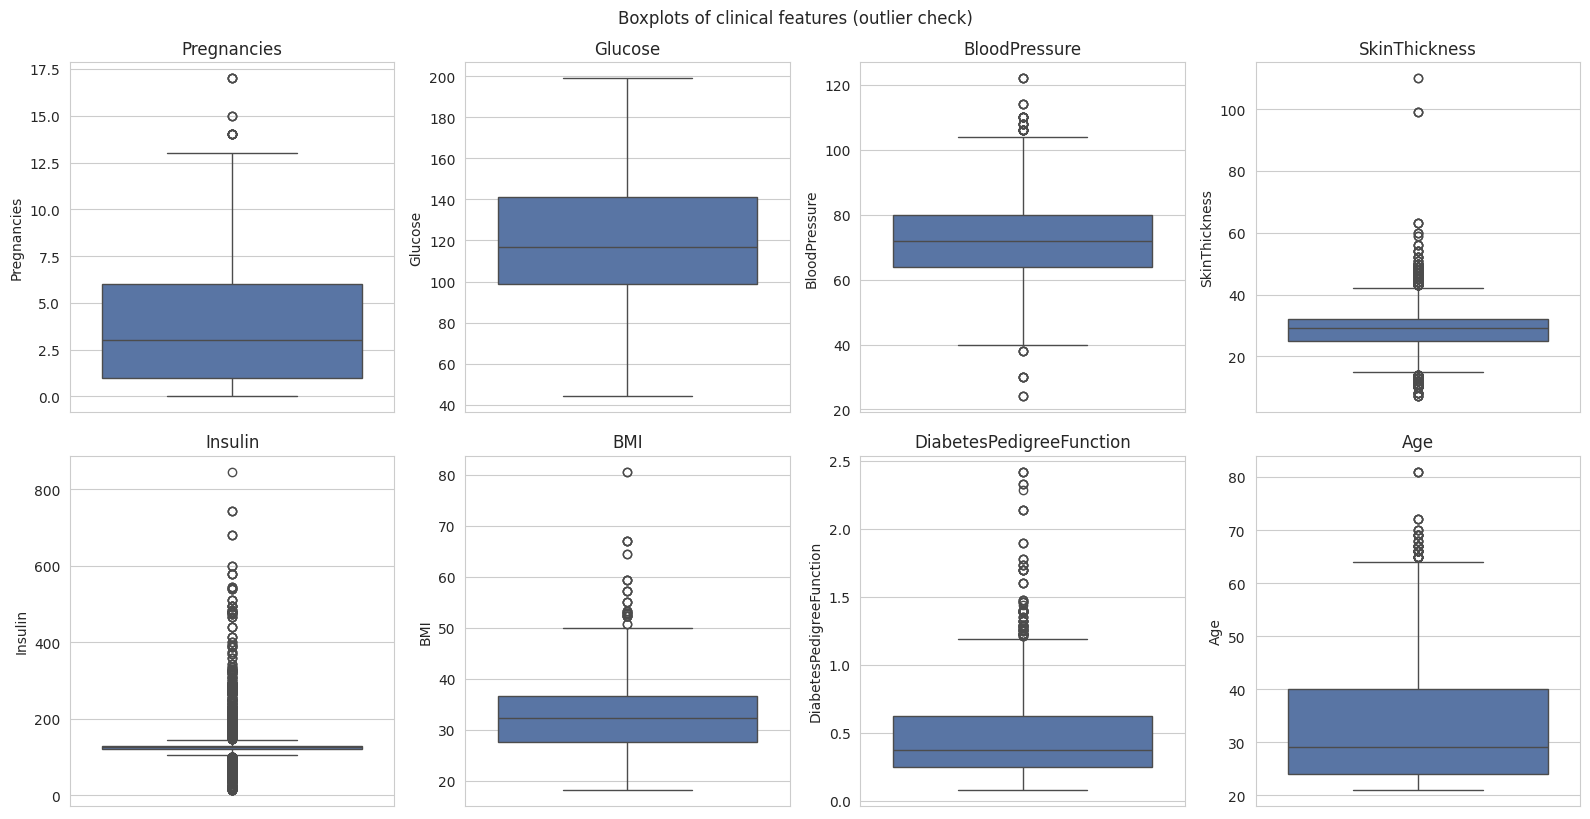

In [ ]:
#boxplot for each clinical feature
feature_cols = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), feature_cols):
    sns.boxplot(y=df_enc[col], ax=ax, color='#4C72B0')
    ax.set_title(col)
plt.tight_layout()
plt.suptitle("Boxplots of clinical features (outlier check)", y=1.02)
plt.show()

In [ ]:
def remove_outliers_iqr(data, cols, k=1.5):
    data = data.copy()
    mask = pd.Series(True, index=data.index)
    for col in cols:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - k*iqr, q3 + k*iqr
        mask &= data[col].between(lower, upper)
    return data[mask]

print("Rows before outlier removal:", len(df_enc))
df_no_outliers = remove_outliers_iqr(df_enc, feature_cols)
print("Rows after outlier removal:", len(df_no_outliers))


Rows before outlier removal: 2768
Rows after outlier removal: 1421


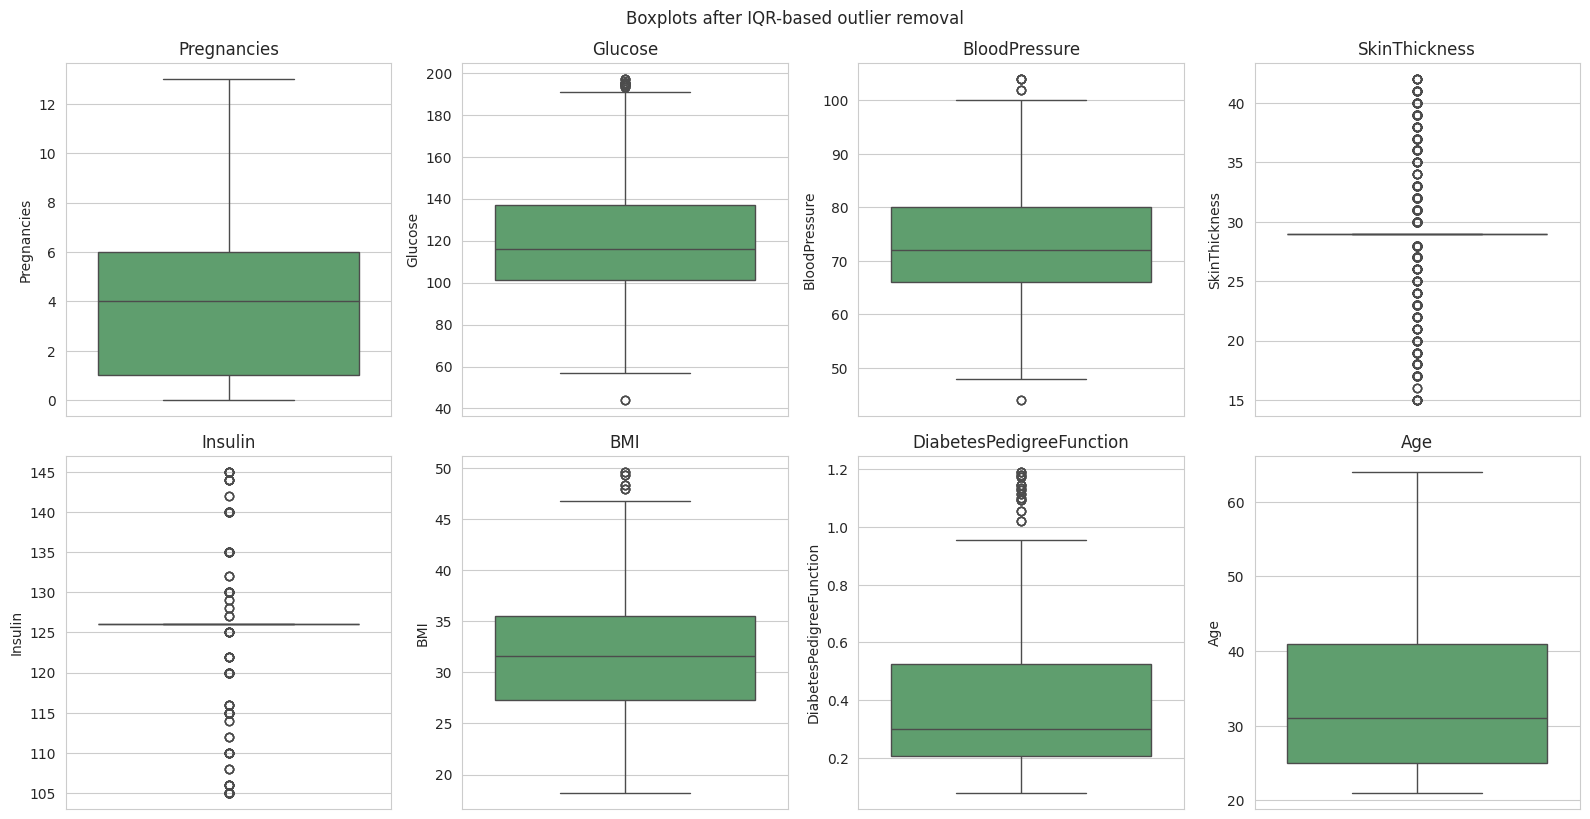

In [ ]:
# EDA visualization for Member 3: boxplot after outlier removal
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), feature_cols):
    sns.boxplot(y=df_no_outliers[col], ax=ax, color='#55A868')
    ax.set_title(col)
plt.tight_layout()
plt.suptitle("Boxplots after IQR-based outlier removal", y=1.02)
plt.show()

**Decision: outliers are investigated but not dropped from the modelling dataset.**

The IQR check above removes rows that fall outside 1.5×IQR on *any* of the 8 clinical features. Applied
across 8 features simultaneously, this is a very strict filter — cumulative across columns, it discards
roughly half the dataset (see figures printed below), and it removes diabetic and non-diabetic patients in
similar proportion. Critically, many of the flagged "outliers" are patients with high Glucose, high Insulin
or high BMI — precisely the values that clinically *define* diabetes risk. Deleting them would not be
removing data-entry errors, it would be removing the very patients the model most needs to learn from, and
would shrink an already small dataset even further.

**Conclusion:** the outlier analysis is kept as an EDA/data-quality investigation (useful insight for Step 2 —
"provide insights and patterns observed in the data"), but `df_no_outliers` is *not* used to build the
final preprocessed file. `df_clean` (deduplicated + missing-value-imputed) is what gets saved and passed to
the six models in Step 3, each of which applies its own additional handling (e.g. scaling) as appropriate.


In [ ]:
# Quantify the cost of applying IQR outlier removal, to justify the decision above
print(f"Rows before outlier removal: {len(df_enc)}")
print(f"Rows after outlier removal: {len(df_no_outliers)}  ({len(df_no_outliers)/len(df_enc):.1%} kept)")
print()
removed_pos = (df_enc['Outcome'] == 1).sum() - (df_no_outliers['Outcome'] == 1).sum()
removed_neg = (df_enc['Outcome'] == 0).sum() - (df_no_outliers['Outcome'] == 0).sum()
print(f"Diabetic patients removed as 'outliers': {removed_pos} of {(df_enc['Outcome'] == 1).sum()}")
print(f"Non-diabetic patients removed as 'outliers': {removed_neg} of {(df_enc['Outcome'] == 0).sum()}")
print("\n-> Outliers are documented here, but NOT dropped from df_clean / the saved file.")


2.4 Normalization / scaling

In [ ]:
scaler = StandardScaler()
df_scaled = df_no_outliers.copy()
df_scaled[feature_cols] = scaler.fit_transform(df_scaled[feature_cols])
df_scaled[feature_cols].describe().T[['mean','std','min','max']]


,mean,std,min,max
Pregnancies,2.500150e-17,1.000352,-1.261515,2.647891
Glucose,-3.500211e-17,1.000352,-2.675460,2.704238
BloodPressure,-3.225194e-16,1.000352,-2.854813,3.059447
SkinThickness,-2.187632e-16,1.000352,-2.743887,2.557488
Insulin,1.181321e-15,1.000352,-3.726835,3.523757
BMI,-5.344071e-16,1.000352,-2.165322,2.843614
DiabetesPedigreeFunction,-1.450087e-16,1.000352,-1.268587,3.246222
Age,2.250135e-17,1.000352,-1.180713,2.758843


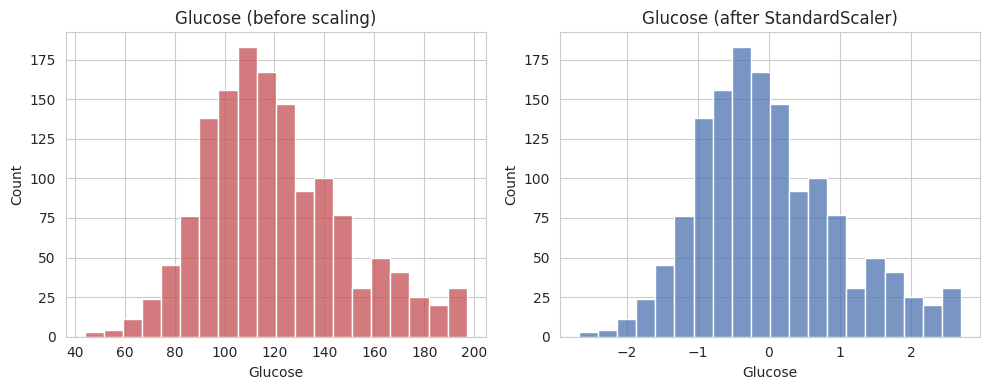

In [ ]:
# EDA visualization for Member 4: before vs after scaling (example: Glucose)
fig, axes = plt.subplots(1, 2, figsize=(10,4))
sns.histplot(df_no_outliers['Glucose'], ax=axes[0], color='#C44E52', bins=20)
axes[0].set_title('Glucose (before scaling)')
sns.histplot(df_scaled['Glucose'], ax=axes[1], color='#4C72B0', bins=20)
axes[1].set_title('Glucose (after StandardScaler)')
plt.tight_layout()
plt.show()


2.5  Feature engineering - feature selection

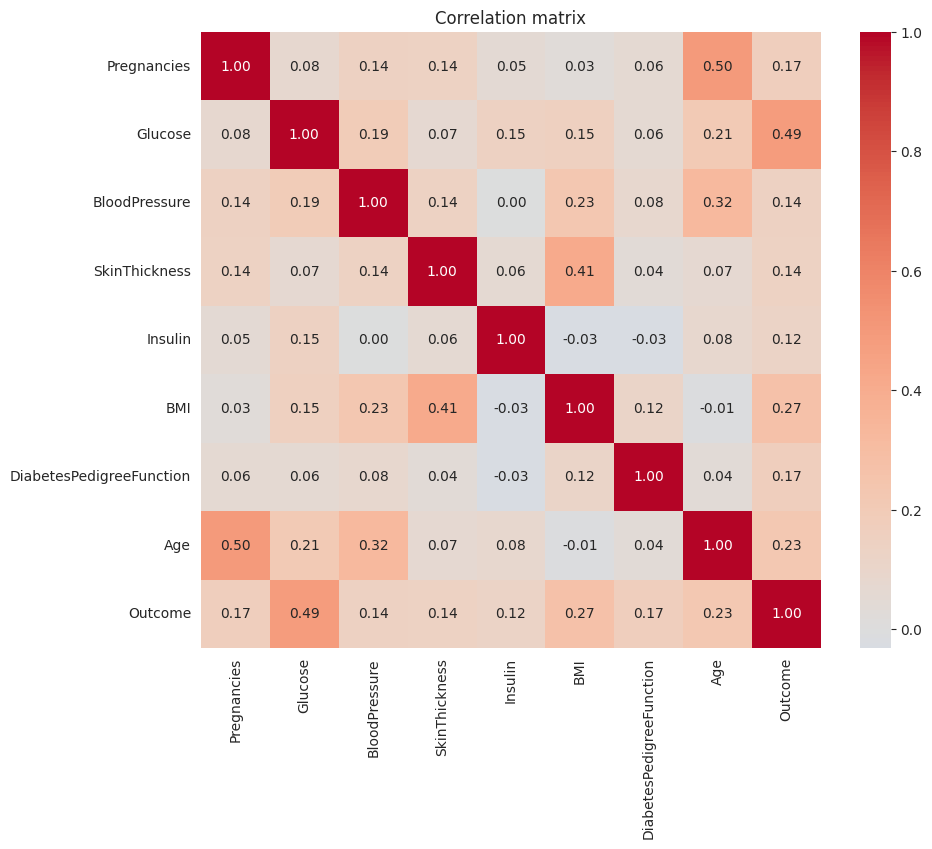

Correlation with target (Outcome):
Glucose                     0.491743
BMI                         0.268123
Age                         0.226405
DiabetesPedigreeFunction    0.166419
Pregnancies                 0.166144
BloodPressure               0.142498
SkinThickness               0.135365
Insulin                     0.121614
Name: Outcome, dtype: float64


In [ ]:
plt.figure(figsize=(10,8))
corr = df_scaled[feature_cols + ['Outcome']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0) #construct a correlation matrix
plt.title('Correlation matrix')
plt.show()

corr_with_target = corr['Outcome'].drop('Outcome').sort_values(ascending=False)
print("Correlation with target (Outcome):")
print(corr_with_target)


In [ ]:
# Select features above a chosen absolute-correlation threshold
threshold = 0.10
selected_features = corr_with_target[abs(corr_with_target) >= threshold].index.tolist()
print(f"Selected features (|corr| >= {threshold}):", selected_features)


Selected features (|corr| >= 0.1): ['Glucose', 'BMI', 'Age', 'DiabetesPedigreeFunction', 'Pregnancies', 'BloodPressure', 'SkinThickness', 'Insulin']


2.6 Feature engineering — dimension reduction (PCA)

In [ ]:
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)  # keep 95% variance
X_pca = pca.fit_transform(df_scaled[feature_cols])

print("Original number of features:", len(feature_cols))
print("Number of PCA components retained:", pca.n_components_)
print("Explained variance ratio per component:", np.round(pca.explained_variance_ratio_, 3))
print("Cumulative explained variance:", np.round(np.cumsum(pca.explained_variance_ratio_), 3))


Original number of features: 8
Number of PCA components retained: 8
Explained variance ratio per component: [0.244 0.169 0.134 0.124 0.114 0.092 0.067 0.055]
Cumulative explained variance: [0.244 0.413 0.547 0.671 0.785 0.878 0.945 1.   ]


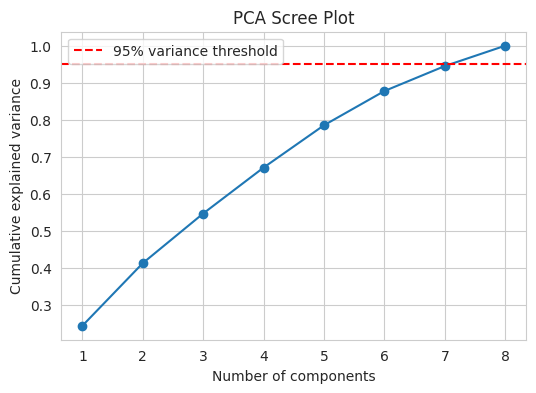

In [ ]:
# EDA visualization for Member 6: cumulative explained variance (scree plot)
plt.figure(figsize=(6,4))
plt.plot(range(1, len(pca.explained_variance_ratio_)+1),
         np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.axhline(0.95, color='red', linestyle='--', label='95% variance threshold')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA Scree Plot')
plt.legend()
plt.show()


In [ ]:
# Final sanity check before saving
print('Final preprocessed shape:', df_clean.shape)
print('Remaining duplicate rows:', df_clean.duplicated(subset=feature_cols_check).sum())
print('Remaining missing values:', df_clean.isnull().sum().sum())

# 1. Save the preprocessed DataFrame to a CSV file in Colab
df_clean.to_csv('preprocessed_data.csv', index=False)

# 2. Trigger an automatic download to your computer
from google.colab import files
files.download('preprocessed_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Step 3: Model Training (Random Forest)

Trained on `df_clean` using the 8 clinical features. Random Forest was picked since it
doesn't need much tuning and works well with the outliers we kept.

### 3.1 Train/test split

In [ ]:
# 80/20 split, stratified so both sets keep the same diabetic/non-diabetic ratio
X = df_clean[feature_cols]
y = df_clean['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("\nClass balance (train):")
print(y_train.value_counts(normalize=True).round(3))

### 3.2 Train the model

In [ ]:
# Scaler + Random Forest in one pipeline
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))
])

rf_model.fit(X_train, y_train)
print("Model trained.")

### 3.3 Evaluate on the held-out test set

In [ ]:
# Metrics on the test set
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-score :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_proba), 3))

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=['No Diabetes', 'Diabetes']))

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes','Diabetes'], yticklabels=['No Diabetes','Diabetes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Random Forest')
plt.show()

In [ ]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_proba):.3f})')
plt.plot([0,1],[0,1],'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.show()

### 3.4 Feature importance

In [ ]:
importances = rf_model.named_steps['clf'].feature_importances_
importance_df = pd.Series(importances, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(7,5))
sns.barplot(x=importance_df.values, y=importance_df.index, color='#4C72B0')
plt.title('Random Forest — Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(importance_df.round(3))

### 3.5 Save the trained model

In [ ]:
import joblib
joblib.dump(rf_model, 'diabetes_rf_model.pkl')

from google.colab import files
files.download('diabetes_rf_model.pkl')

print("Model saved: diabetes_rf_model.pkl")